In [39]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

import random
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [41]:
print("PyTorch Version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
    device = torch.device("cuda")
else:
    print("GPU not available. Using CPU.")
    device = torch.device("cpu")

print("Selected Device:", device)

PyTorch Version: 2.15.0+cpu
GPU not available. Using CPU.
Selected Device: cpu


In [42]:
# Load cleaned Kepler dataset
kepler_dl = pd.read_csv("../data/processed/kepler_clean.csv")

# Selected features from Notebook 03
feature_names = [
    'koi_period', 'koi_time0bk', 'koi_time0',
    'koi_impact', 'koi_duration', 'koi_depth',
    'koi_ror', 'koi_srho', 'koi_prad', 'koi_sma',
    'koi_incl', 'koi_teq', 'koi_insol', 'koi_dor',
    'koi_ldm_coeff2', 'koi_ldm_coeff1', 'koi_model_snr',
    'koi_count', 'koi_steff', 'koi_slogg', 'koi_smet',
    'koi_srad', 'koi_smass', 'koi_kepmag', 'koi_gmag',
    'koi_rmag', 'koi_imag', 'koi_zmag', 'koi_jmag',
    'koi_hmag', 'koi_kmag'
]

X_raw = kepler_dl[feature_names].copy()
y_raw = kepler_dl['koi_disposition'].copy()
groups_raw = kepler_dl['kepid'].copy()

print("Dataset loaded successfully!")
print("Features:", X_raw.shape)
print("Target:", y_raw.shape)
print("Unique host stars:", groups_raw.nunique())

Dataset loaded successfully!
Features: (9564, 31)
Target: (9564,)
Unique host stars: 8214


In [43]:
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X_raw, y_raw, groups=groups_raw)
)

X_train_raw = X_raw.iloc[train_idx].copy()
X_test_raw = X_raw.iloc[test_idx].copy()

y_train_cv = y_raw.iloc[train_idx].copy()
y_test = y_raw.iloc[test_idx].copy()

groups_train_cv = groups_raw.iloc[train_idx].copy()
groups_test = groups_raw.iloc[test_idx].copy()

print("Training shape:", X_train_raw.shape)
print("Testing shape:", X_test_raw.shape)

print("\nTraining distribution:")
print(y_train_cv.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

print(
    "\nOverlapping host stars:",
    len(set(groups_train_cv) & set(groups_test))
)

Training shape: (7650, 31)
Testing shape: (1914, 31)

Training distribution:
koi_disposition
FALSE POSITIVE    3871
CONFIRMED         2198
CANDIDATE         1581
Name: count, dtype: int64

Testing distribution:
koi_disposition
FALSE POSITIVE    968
CONFIRMED         550
CANDIDATE         396
Name: count, dtype: int64

Overlapping host stars: 0


In [44]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

dl_train_idx, dl_val_idx = next(
    cv.split(
        X_train_raw,
        y_train_cv,
        groups=groups_train_cv
    )
)

X_dl_train = X_train_raw.iloc[dl_train_idx].copy()
X_dl_val = X_train_raw.iloc[dl_val_idx].copy()

y_dl_train = y_train_cv.iloc[dl_train_idx].copy()
y_dl_val = y_train_cv.iloc[dl_val_idx].copy()

groups_dl_train = groups_train_cv.iloc[dl_train_idx]
groups_dl_val = groups_train_cv.iloc[dl_val_idx]

print("DL Training:", X_dl_train.shape)
print("DL Validation:", X_dl_val.shape)

print(
    "Overlapping host stars:",
    len(set(groups_dl_train) & set(groups_dl_val))
)

DL Training: (6118, 31)
DL Validation: (1532, 31)
Overlapping host stars: 0


In [45]:
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

# Fit only on the inner training fold
X_dl_train = imputer.fit_transform(X_dl_train)

# Transform validation using training statistics
X_dl_val = imputer.transform(X_dl_val)

X_dl_train = scaler.fit_transform(X_dl_train)
X_dl_val = scaler.transform(X_dl_val)

print("Training shape:", X_dl_train.shape)
print("Validation shape:", X_dl_val.shape)

print("Training missing values:", np.isnan(X_dl_train).sum())
print("Validation missing values:", np.isnan(X_dl_val).sum())

Training shape: (6118, 31)
Validation shape: (1532, 31)
Training missing values: 0
Validation missing values: 0


In [46]:
class_names = [
    'CANDIDATE',
    'CONFIRMED',
    'FALSE POSITIVE'
]

dl_label_encoder = LabelEncoder()
dl_label_encoder.fit(class_names)

y_dl_train_encoded = dl_label_encoder.transform(y_dl_train)
y_dl_val_encoded = dl_label_encoder.transform(y_dl_val)

print("Class mapping:")

for index, class_name in enumerate(dl_label_encoder.classes_):
    print(f"{class_name}: {index}")

Class mapping:
CANDIDATE: 0
CONFIRMED: 1
FALSE POSITIVE: 2


In [47]:
# Convert features
X_train_tensor = torch.tensor(
    X_dl_train,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_dl_val,
    dtype=torch.float32
)

# Convert labels
y_train_tensor = torch.tensor(
    y_dl_train_encoded,
    dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_dl_val_encoded,
    dtype=torch.long
)

print("Training feature tensor:", X_train_tensor.shape)
print("Training target tensor:", y_train_tensor.shape)

print("Validation feature tensor:", X_val_tensor.shape)
print("Validation target tensor:", y_val_tensor.shape)

Training feature tensor: torch.Size([6118, 31])
Training target tensor: torch.Size([6118])
Validation feature tensor: torch.Size([1532, 31])
Validation target tensor: torch.Size([1532])


In [48]:
batch_size = 64

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 96
Validation batches: 24


In [49]:
class ExoplanetMLP(nn.Module):

    def __init__(self, input_size, num_classes):

        super(ExoplanetMLP, self).__init__()

        self.network = nn.Sequential(

            # First hidden layer
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Second hidden layer
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Output layer
            nn.Linear(32, num_classes)

        )

    def forward(self, x):
        return self.network(x)

In [50]:
input_size = X_train_tensor.shape[1]
num_classes = len(dl_label_encoder.classes_)

model = ExoplanetMLP(
    input_size=input_size,
    num_classes=num_classes
).to(device)

print(model)

ExoplanetMLP(
  (network): Sequential(
    (0): Linear(in_features=31, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=3, bias=True)
  )
)


In [51]:
total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total trainable parameters:", total_params)

Total trainable parameters: 4227


In [52]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("Loss Function:", criterion)
print("Optimizer:", optimizer)

Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


In [53]:
num_epochs = 100
patience = 12
min_delta = 0.0001

best_val_loss = float('inf')
epochs_without_improvement = 0

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_model_state = None

In [63]:
for epoch in range(num_epochs):

    # -------------------------
    # TRAINING
    # -------------------------

    model.train()

    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item() * inputs.size(0)

        predictions = torch.argmax(outputs, dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    epoch_train_loss = running_train_loss / train_total
    epoch_train_accuracy = train_correct / train_total


    # -------------------------
    # VALIDATION
    # -------------------------

    model.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for inputs, labels in val_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * inputs.size(0)

            predictions = torch.argmax(outputs, dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = running_val_loss / val_total
    epoch_val_accuracy = val_correct / val_total


    # -------------------------
    # SAVE METRICS
    # -------------------------

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    train_accuracies.append(epoch_train_accuracy)
    val_accuracies.append(epoch_val_accuracy)


    # -------------------------
    # EARLY STOPPING
    # -------------------------

    if epoch_val_loss < best_val_loss - min_delta:

        best_val_loss = epoch_val_loss

        best_model_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    # -------------------------
    # PRINT PROGRESS
    # -------------------------

    if (epoch + 1) % 5 == 0 or epoch == 0:

        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"Train Loss: {epoch_train_loss:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f} | "
            f"Train Acc: {epoch_train_accuracy:.4f} | "
            f"Val Acc: {epoch_val_accuracy:.4f}"
        )


    if epochs_without_improvement >= patience:

        print(f"\nEarly stopping triggered at epoch {epoch+1}")
        break


# Restore the best model
model.load_state_dict(best_model_state)

print("\nTraining completed!")
print("Best Validation Loss:", round(best_val_loss, 4))

Epoch [1/100] Train Loss: 0.9834 | Val Loss: 0.8362 | Train Acc: 0.5919 | Val Acc: 0.6436
Epoch [5/100] Train Loss: 0.7776 | Val Loss: 0.7589 | Train Acc: 0.6599 | Val Acc: 0.6625
Epoch [10/100] Train Loss: 0.7586 | Val Loss: 0.7431 | Train Acc: 0.6648 | Val Acc: 0.6664
Epoch [15/100] Train Loss: 0.7318 | Val Loss: 0.7317 | Train Acc: 0.6780 | Val Acc: 0.6802
Epoch [20/100] Train Loss: 0.7269 | Val Loss: 0.7223 | Train Acc: 0.6858 | Val Acc: 0.6678
Epoch [25/100] Train Loss: 0.7124 | Val Loss: 0.7281 | Train Acc: 0.6907 | Val Acc: 0.6749
Epoch [30/100] Train Loss: 0.7021 | Val Loss: 0.7140 | Train Acc: 0.6947 | Val Acc: 0.6749
Epoch [35/100] Train Loss: 0.6974 | Val Loss: 0.7207 | Train Acc: 0.6950 | Val Acc: 0.6789

Early stopping triggered at epoch 39

Training completed!
Best Validation Loss: 0.7101


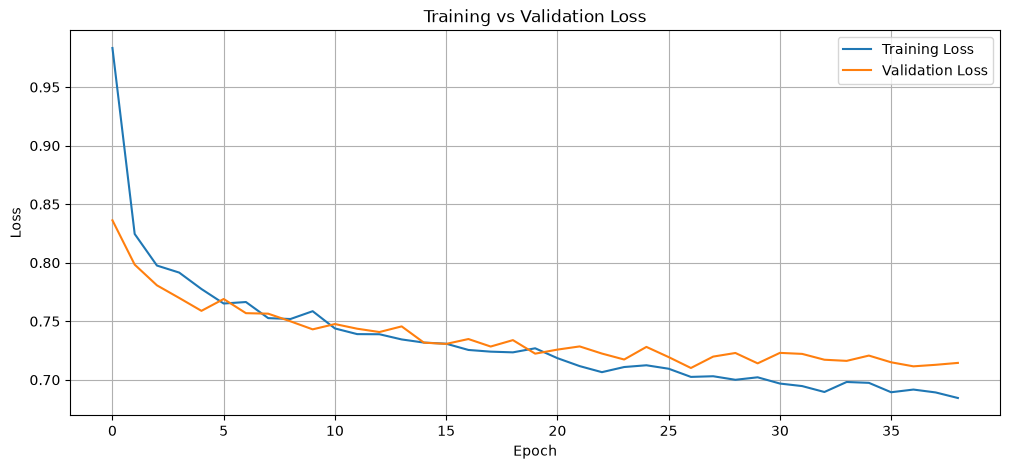

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

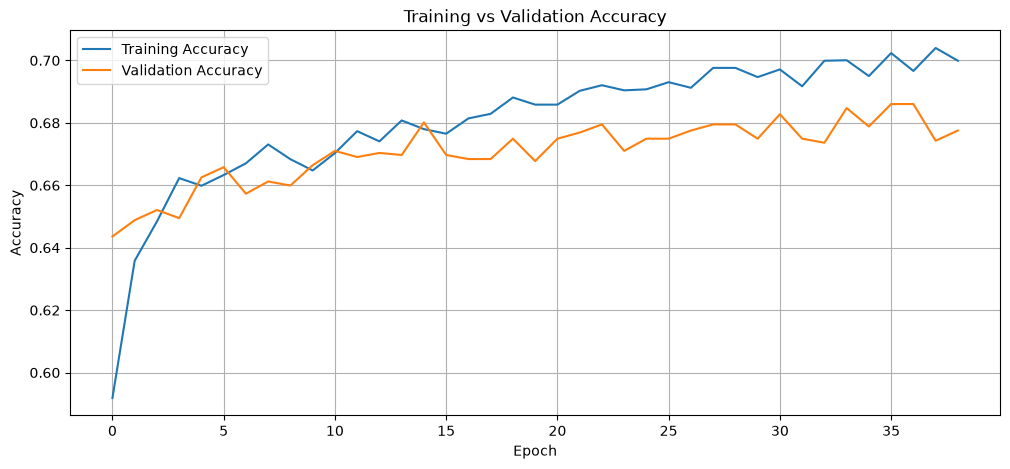

In [65]:
plt.figure(figsize=(12, 5))

plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [67]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)
import numpy as np

model.eval()

all_predictions = []
all_actuals = []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)

        outputs = model(inputs)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_actuals.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_actuals = np.array(all_actuals)

print("Validation Accuracy:",
      accuracy_score(all_actuals, all_predictions))

print("Validation Macro F1:",
      f1_score(all_actuals, all_predictions, average='macro'))

print("Validation Balanced Accuracy:",
      balanced_accuracy_score(all_actuals, all_predictions))

print("\nClassification Report:\n")

print(classification_report(
    all_actuals,
    all_predictions,
    target_names=dl_label_encoder.classes_
))

print("Confusion Matrix:\n")

print(confusion_matrix(all_actuals, all_predictions))

Validation Accuracy: 0.6775456919060052
Validation Macro F1: 0.6516422271546626
Validation Balanced Accuracy: 0.664700361712166

Classification Report:

                precision    recall  f1-score   support

     CANDIDATE       0.39      0.57      0.46       317
     CONFIRMED       0.71      0.73      0.72       440
FALSE POSITIVE       0.87      0.69      0.77       775

      accuracy                           0.68      1532
     macro avg       0.66      0.66      0.65      1532
  weighted avg       0.73      0.68      0.69      1532

Confusion Matrix:

[[181  81  55]
 [ 94 323  23]
 [191  50 534]]


In [58]:
import torch
import torch.nn as nn
import torch.optim as optim

class_counts = torch.bincount(y_train_tensor)

num_classes = len(class_counts)
total_samples = len(y_train_tensor)

class_weights = total_samples / (num_classes * class_counts.float())

class_weights = class_weights.to(device)

print("Class counts:")
for class_name, count in zip(
    dl_label_encoder.classes_,
    class_counts
):
    print(f"{class_name}: {count.item()}")

print("\nClass weights:")
for class_name, weight in zip(
    dl_label_encoder.classes_,
    class_weights
):
    print(f"{class_name}: {weight.item():.4f}")

Class counts:
CANDIDATE: 1264
CONFIRMED: 1758
FALSE POSITIVE: 3096

Class weights:
CANDIDATE: 1.6134
CONFIRMED: 1.1600
FALSE POSITIVE: 0.6587


In [59]:
torch.manual_seed(42)

model = ExoplanetMLP(
    input_size=31,
    num_classes=3
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("New MLP initialized!")
print("Loss function:", criterion)
print("Optimizer:", optimizer)

New MLP initialized!
Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


In [60]:
num_epochs = 100
patience = 12
min_delta = 0.0001

best_val_loss = float('inf')
epochs_without_improvement = 0

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_model_state = None

In [68]:
import numpy as np

unique, counts = np.unique(
    all_predictions,
    return_counts=True
)

print("Predicted class distribution:")

for class_id, count in zip(unique, counts):
    class_name = dl_label_encoder.inverse_transform([class_id])[0]

    print(
        f"{class_name}: {count} "
        f"({count / len(all_predictions) * 100:.2f}%)"
    )

Predicted class distribution:
CANDIDATE: 466 (30.42%)
CONFIRMED: 454 (29.63%)
FALSE POSITIVE: 612 (39.95%)


In [66]:
print("Training history length:", len(train_losses))
print("Validation history length:", len(val_losses))

if len(train_losses) > 0:
    print("\nFinal training loss:", train_losses[-1])
    print("Minimum training loss:", min(train_losses))
    print("Final training accuracy:", train_accuracies[-1])

if len(val_losses) > 0:
    print("\nFinal validation loss:", val_losses[-1])
    print("Minimum validation loss:", min(val_losses))
    print("Final validation accuracy:", val_accuracies[-1])

print("\nBest validation loss:", best_val_loss)

Training history length: 39
Validation history length: 39

Final training loss: 0.6844640221616028
Minimum training loss: 0.6844640221616028
Final training accuracy: 0.6999019287348807

Final validation loss: 0.7144391715682207
Minimum validation loss: 0.7100928400888766
Final validation accuracy: 0.6775456919060052

Best validation loss: 0.7100928400888766


In [69]:
# Check important variables available in the notebook

variables_to_check = [
    'X_train', 'X_test',
    'y_train', 'y_test',
    'X_dl_train', 'X_dl_val',
    'y_dl_train', 'y_dl_val',
    'feature_names', 'groups_train',
    'class_weights', 'class_names'
]

for var in variables_to_check:
    if var in globals():
        value = globals()[var]

        if hasattr(value, 'shape'):
            print(f"{var}: Available | Shape: {value.shape}")
        else:
            print(f"{var}: Available")
    else:
        print(f"{var}: Not available")

X_train: Not available
X_test: Not available
y_train: Not available
y_test: Available | Shape: (1914,)
X_dl_train: Available | Shape: (6118, 31)
X_dl_val: Available | Shape: (1532, 31)
y_dl_train: Available | Shape: (6118,)
y_dl_val: Available | Shape: (1532,)
feature_names: Available
groups_train: Not available
class_weights: Available | Shape: torch.Size([3])
class_names: Available


In [70]:
import pandas as pd
import numpy as np

print("DATAFRAMES AVAILABLE:")
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

print("\nIMPORTANT VARIABLES:")
for name in globals().copy():
    if any(word in name.lower() for word in
           ['train', 'test', 'group', 'split', 'target', 'label']):
        obj = globals()[name]

        if isinstance(obj, (pd.Series, pd.DataFrame, np.ndarray)):
            print(f"{name}: {obj.shape}")

DATAFRAMES AVAILABLE:
kepler_dl: (9564, 114)
X_raw: (9564, 31)
X_train_raw: (7650, 31)
X_test_raw: (1914, 31)

IMPORTANT VARIABLES:
groups_raw: (9564,)
train_idx: (7650,)
test_idx: (1914,)
X_train_raw: (7650, 31)
X_test_raw: (1914, 31)
y_train_cv: (7650,)
y_test: (1914,)
groups_train_cv: (7650,)
groups_test: (1914,)
dl_train_idx: (6118,)
X_dl_train: (6118, 31)
y_dl_train: (6118,)
groups_dl_train: (6118,)
groups_dl_val: (1532,)
y_dl_train_encoded: (6118,)


In [71]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder

# 1. Create fresh preprocessing objects
final_imputer = SimpleImputer(strategy='median')
final_scaler = StandardScaler()

# 2. Fit and transform training features
X_final_train = final_imputer.fit_transform(X_train_raw)
X_final_train = final_scaler.fit_transform(X_final_train)

# 3. Transform test features using training-fitted objects
X_final_test = final_imputer.transform(X_test_raw)
X_final_test = final_scaler.transform(X_final_test)

# 4. Encode target labels
final_label_encoder = LabelEncoder()

y_final_train = final_label_encoder.fit_transform(y_train_cv)
y_final_test = final_label_encoder.transform(y_test)

# 5. Display results
print("FINAL PREPROCESSING COMPLETED")
print("-" * 45)

print("Training features:", X_final_train.shape)
print("Testing features:", X_final_test.shape)

print("\nClass mapping:")
for index, label in enumerate(final_label_encoder.classes_):
    print(f"{label}: {index}")

print("\nTraining missing values:", np.isnan(X_final_train).sum())
print("Testing missing values:", np.isnan(X_final_test).sum())

print("\nTraining class distribution:")
print(pd.Series(y_final_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_final_test).value_counts().sort_index())

FINAL PREPROCESSING COMPLETED
---------------------------------------------
Training features: (7650, 31)
Testing features: (1914, 31)

Class mapping:
CANDIDATE: 0
CONFIRMED: 1
FALSE POSITIVE: 2

Training missing values: 0
Testing missing values: 0

Training class distribution:
0    1581
1    2198
2    3871
Name: count, dtype: int64

Testing class distribution:
0    396
1    550
2    968
Name: count, dtype: int64


In [72]:
import torch
import numpy as np

# Calculate class weights from the complete training set
class_counts = np.bincount(y_final_train)

num_classes = len(class_counts)
total_samples = len(y_final_train)

weights = total_samples / (num_classes * class_counts)

final_class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(device)

print("FINAL CLASS WEIGHTS")
print("-" * 35)

for i, label in enumerate(final_label_encoder.classes_):
    print(f"{label}: {final_class_weights[i].item():.4f}")

FINAL CLASS WEIGHTS
-----------------------------------
CANDIDATE: 1.6129
CONFIRMED: 1.1601
FALSE POSITIVE: 0.6587


In [73]:
import torch.nn as nn
import torch.optim as optim

# Define the final model
final_model = ExoplanetMLP(
    input_size=X_final_train.shape[1],
    num_classes=len(final_label_encoder.classes_)
).to(device)

# Weighted loss function
final_criterion = nn.CrossEntropyLoss(
    weight=final_class_weights
)

# Adam optimizer
final_optimizer = optim.Adam(
    final_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Display model information
total_params = sum(
    p.numel() for p in final_model.parameters()
    if p.requires_grad
)

print("FINAL MLP INITIALIZED")
print("-" * 40)
print(final_model)
print("\nTrainable parameters:", total_params)
print("Learning rate: 0.001")
print("Weight decay: 0.0001")
print("Loss function: Weighted CrossEntropyLoss")
print("Optimizer: Adam")


FINAL MLP INITIALIZED
----------------------------------------
ExoplanetMLP(
  (network): Sequential(
    (0): Linear(in_features=31, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=3, bias=True)
  )
)

Trainable parameters: 4227
Learning rate: 0.001
Weight decay: 0.0001
Loss function: Weighted CrossEntropyLoss
Optimizer: Adam


In [74]:
# Find the epoch with the lowest validation loss
best_epoch = int(np.argmin(val_losses)) + 1

print("BEST EPOCH:", best_epoch)
print("BEST VALIDATION LOSS:", min(val_losses))
print("TOTAL VALIDATION TRAINING EPOCHS:", len(val_losses))

BEST EPOCH: 27
BEST VALIDATION LOSS: 0.7100928400888766
TOTAL VALIDATION TRAINING EPOCHS: 39


In [75]:
from torch.utils.data import TensorDataset, DataLoader

# Convert complete training data into tensors
X_final_train_tensor = torch.tensor(
    X_final_train, dtype=torch.float32
)

y_final_train_tensor = torch.tensor(
    y_final_train, dtype=torch.long
)

# Create DataLoader
final_dataset = TensorDataset(
    X_final_train_tensor,
    y_final_train_tensor
)

final_loader = DataLoader(
    final_dataset,
    batch_size=64,
    shuffle=True
)

# Final training
final_train_losses = []
final_train_accuracies = []

for epoch in range(best_epoch):

    final_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_X, batch_y in final_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        # Clear previous gradients
        final_optimizer.zero_grad()

        # Forward pass
        outputs = final_model(batch_X)

        # Calculate weighted loss
        loss = final_criterion(outputs, batch_y)

        # Backpropagation
        loss.backward()

        # Update weights
        final_optimizer.step()

        running_loss += loss.item() * batch_X.size(0)

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == batch_y).sum().item()
        total += batch_y.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    final_train_losses.append(epoch_loss)
    final_train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch + 1}/{best_epoch}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.4f}"
    )

print("\nFINAL TRAINING COMPLETED!")

Epoch [1/27] Loss: 0.9530 Accuracy: 0.6022
Epoch [2/27] Loss: 0.8159 Accuracy: 0.6320
Epoch [3/27] Loss: 0.7955 Accuracy: 0.6545
Epoch [4/27] Loss: 0.7818 Accuracy: 0.6488
Epoch [5/27] Loss: 0.7782 Accuracy: 0.6550
Epoch [6/27] Loss: 0.7678 Accuracy: 0.6579
Epoch [7/27] Loss: 0.7567 Accuracy: 0.6681
Epoch [8/27] Loss: 0.7588 Accuracy: 0.6644
Epoch [9/27] Loss: 0.7510 Accuracy: 0.6715
Epoch [10/27] Loss: 0.7499 Accuracy: 0.6697
Epoch [11/27] Loss: 0.7450 Accuracy: 0.6748
Epoch [12/27] Loss: 0.7404 Accuracy: 0.6727
Epoch [13/27] Loss: 0.7392 Accuracy: 0.6715
Epoch [14/27] Loss: 0.7335 Accuracy: 0.6805
Epoch [15/27] Loss: 0.7320 Accuracy: 0.6767
Epoch [16/27] Loss: 0.7265 Accuracy: 0.6769
Epoch [17/27] Loss: 0.7233 Accuracy: 0.6816
Epoch [18/27] Loss: 0.7295 Accuracy: 0.6803
Epoch [19/27] Loss: 0.7204 Accuracy: 0.6834
Epoch [20/27] Loss: 0.7209 Accuracy: 0.6858
Epoch [21/27] Loss: 0.7210 Accuracy: 0.6822
Epoch [22/27] Loss: 0.7219 Accuracy: 0.6894
Epoch [23/27] Loss: 0.7162 Accuracy: 0.68

In [76]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Convert test data into tensors
X_final_test_tensor = torch.tensor(
    X_final_test, dtype=torch.float32
).to(device)

# Evaluation mode
final_model.eval()

# Generate predictions
with torch.no_grad():
    test_outputs = final_model(X_final_test_tensor)
    y_test_pred = torch.argmax(test_outputs, dim=1).cpu().numpy()

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_final_test, y_test_pred)

test_precision = precision_score(
    y_final_test, y_test_pred, average='macro'
)

test_recall = recall_score(
    y_final_test, y_test_pred, average='macro'
)

test_f1 = f1_score(
    y_final_test, y_test_pred, average='macro'
)

test_balanced_accuracy = balanced_accuracy_score(
    y_final_test, y_test_pred
)

# Display metrics
print("FINAL WEIGHTED MLP - TEST RESULTS")
print("=" * 50)

print(f"Accuracy:          {test_accuracy:.4f}")
print(f"Macro Precision:   {test_precision:.4f}")
print(f"Macro Recall:      {test_recall:.4f}")
print(f"Macro F1-Score:    {test_f1:.4f}")
print(f"Balanced Accuracy: {test_balanced_accuracy:.4f}")

print("\nCLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_final_test,
    y_test_pred,
    target_names=final_label_encoder.classes_,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(
    y_final_test,
    y_test_pred
)

print("CONFUSION MATRIX")
print(cm)

FINAL WEIGHTED MLP - TEST RESULTS
Accuracy:          0.6949
Macro Precision:   0.6658
Macro Recall:      0.6773
Macro F1-Score:    0.6641
Balanced Accuracy: 0.6773

CLASSIFICATION REPORT
                precision    recall  f1-score   support

     CANDIDATE     0.3981    0.5379    0.4576       396
     CONFIRMED     0.7133    0.7873    0.7485       550
FALSE POSITIVE     0.8860    0.7066    0.7862       968

      accuracy                         0.6949      1914
     macro avg     0.6658    0.6773    0.6641      1914
  weighted avg     0.7355    0.6949    0.7074      1914

CONFUSION MATRIX
[[213 114  69]
 [ 98 433  19]
 [224  60 684]]


In [77]:
import os
import joblib
import json

# Create models directory
os.makedirs("models", exist_ok=True)

# 1. Save PyTorch model
torch.save(
    {
        "model_state_dict": final_model.state_dict(),
        "input_size": 31,
        "num_classes": 3,
        "hidden_layers": [64, 32],
        "dropout": [0.3, 0.2],
        "classes": final_label_encoder.classes_.tolist()
    },
    "models/exodetect_weighted_mlp.pth"
)

# 2. Save preprocessing objects
joblib.dump(
    final_imputer,
    "models/dl_imputer.pkl"
)

joblib.dump(
    final_scaler,
    "models/dl_scaler.pkl"
)

joblib.dump(
    final_label_encoder,
    "models/dl_label_encoder.pkl"
)

# 3. Save feature names
with open("models/dl_feature_names.json", "w") as file:
    json.dump(feature_names, file, indent=4)

print("ALL DEEP LEARNING ARTIFACTS SAVED!")
print("-" * 45)

print(os.listdir("models"))

ALL DEEP LEARNING ARTIFACTS SAVED!
---------------------------------------------
['dl_feature_names.json', 'dl_imputer.pkl', 'dl_label_encoder.pkl', 'dl_scaler.pkl', 'exodetect_weighted_mlp.pth']


In [78]:
from pathlib import Path
import shutil

# Identify project root
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

# Define directories
source_dir = project_root / "notebooks" / "models"
destination_dir = project_root / "models"

destination_dir.mkdir(exist_ok=True)

# Move all deep learning artifacts
for file in source_dir.iterdir():

    if file.is_file():
        destination = destination_dir / file.name

        shutil.copy2(file, destination)

        print(f"Copied: {file.name}")

print("\nFINAL MODEL DIRECTORY:")
for file in destination_dir.iterdir():
    if file.is_file():
        print(file.name)

Copied: dl_feature_names.json
Copied: dl_imputer.pkl
Copied: dl_label_encoder.pkl
Copied: dl_scaler.pkl
Copied: exodetect_weighted_mlp.pth

FINAL MODEL DIRECTORY:
dl_feature_names.json
dl_imputer.pkl
dl_label_encoder.pkl
dl_scaler.pkl
exodetect_catboost_final.pkl
exodetect_weighted_mlp.pth
kepler_preprocessing_pipeline.pkl


In [79]:
import torch
import joblib
import json
from pathlib import Path
import numpy as np

# Identify project root
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

model_dir = project_root / "models"

# 1. Load preprocessing artifacts
loaded_imputer = joblib.load(model_dir / "dl_imputer.pkl")
loaded_scaler = joblib.load(model_dir / "dl_scaler.pkl")
loaded_encoder = joblib.load(model_dir / "dl_label_encoder.pkl")

with open(model_dir / "dl_feature_names.json", "r") as file:
    loaded_features = json.load(file)

# 2. Initialize model architecture
loaded_model = ExoplanetMLP(
    input_size=31,
    num_classes=3
).to(device)

# 3. Load saved weights
checkpoint = torch.load(
    model_dir / "exodetect_weighted_mlp.pth",
    map_location=device,
    weights_only=True
)

loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model.eval()

# 4. Generate predictions using loaded model
with torch.no_grad():
    loaded_outputs = loaded_model(X_final_test_tensor)
    loaded_predictions = torch.argmax(
        loaded_outputs, dim=1
    ).cpu().numpy()

# 5. Compare predictions
predictions_match = np.array_equal(
    y_test_pred,
    loaded_predictions
)

print("MODEL VERIFICATION RESULTS")
print("=" * 45)

print("Model loaded successfully!")
print("Imputer loaded successfully!")
print("Scaler loaded successfully!")
print("Label encoder loaded successfully!")

print("\nFeature count:", len(loaded_features))
print("Class mapping:", loaded_encoder.classes_)

print("\nOriginal and loaded predictions match:", predictions_match)
print("Test predictions generated:", len(loaded_predictions))

MODEL VERIFICATION RESULTS
Model loaded successfully!
Imputer loaded successfully!
Scaler loaded successfully!
Label encoder loaded successfully!

Feature count: 31
Class mapping: ['CANDIDATE' 'CONFIRMED' 'FALSE POSITIVE']

Original and loaded predictions match: True
Test predictions generated: 1914


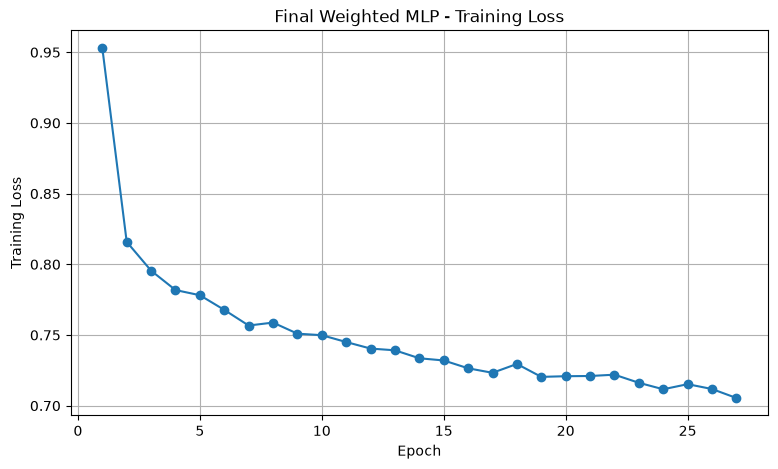

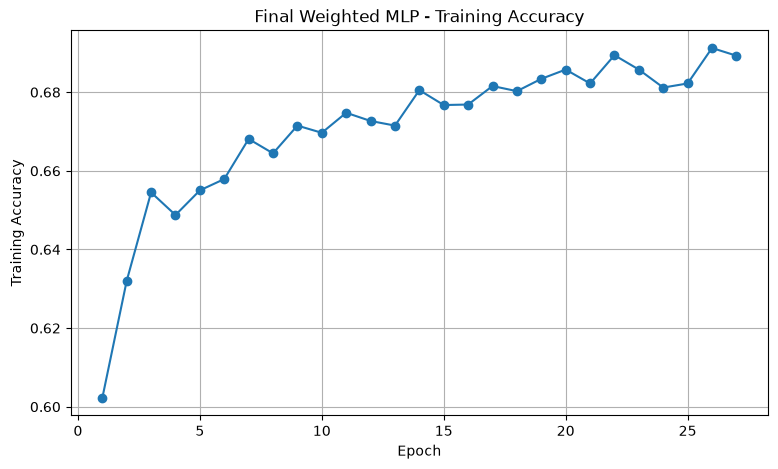

In [80]:
import matplotlib.pyplot as plt

epochs = range(1, len(final_train_losses) + 1)

# Training Loss
plt.figure(figsize=(9, 5))
plt.plot(epochs, final_train_losses, marker='o')
plt.title("Final Weighted MLP - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.grid(True)
plt.show()

# Training Accuracy
plt.figure(figsize=(9, 5))
plt.plot(epochs, final_train_accuracies, marker='o')
plt.title("Final Weighted MLP - Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.grid(True)
plt.show()

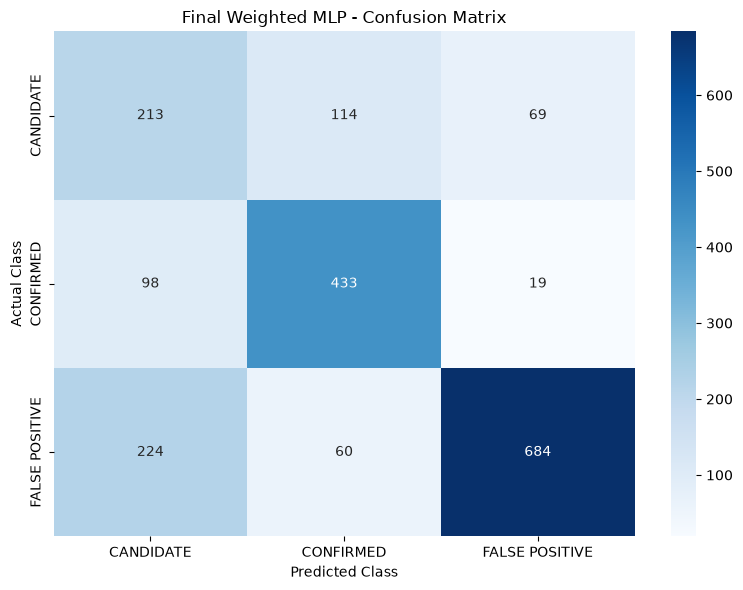

In [81]:
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=final_label_encoder.classes_,
    yticklabels=final_label_encoder.classes_
)

plt.title("Final Weighted MLP - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

In [82]:
import json
from pathlib import Path

evaluation_results = {
    "model": "Weighted MLP",
    "test_samples": int(len(y_final_test)),
    "accuracy": float(test_accuracy),
    "macro_precision": float(test_precision),
    "macro_recall": float(test_recall),
    "macro_f1": float(test_f1),
    "balanced_accuracy": float(test_balanced_accuracy),
    "training_epochs": int(best_epoch),
    "training_samples": int(len(y_final_train)),
    "features": int(X_final_train.shape[1]),
    "confusion_matrix": cm.tolist()
}

results_path = model_dir / "weighted_mlp_results.json"

with open(results_path, "w") as file:
    json.dump(evaluation_results, file, indent=4)

print("Evaluation results saved successfully!")
print(results_path)

Evaluation results saved successfully!
c:\David Mills\projects\NASAexoplanet\models\weighted_mlp_results.json
